# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này hoàn chỉnh toàn bộ mã huấn luyện và suy luận theo chuẩn đề bài.


## 0. Môi trường (Colab T4)


In [6]:
# Runtime → Change runtime type → T4 GPU
!git clone https://github.com/tranthai239/K4-Track-4-Day10-VisionLanguageModel.git
%cd K4-Track-4-Day10-VisionLanguageModel

!nvidia-smi -L
!pip -q install -r requirements-colab.txt


Cloning into 'K4-Track-4-Day10-VisionLanguageModel'...
remote: Enumerating objects: 64, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 64 (delta 7), reused 6 (delta 6), pack-reused 48 (from 1)
Receiving objects: 100% (64/64), 118.75 KiB | 23.75 MiB/s, done.
Resolving deltas: 100% (10/10), done.
/content/K4-Track-4-Day10-VisionLanguageModel
GPU 0: Tesla T4 (UUID: GPU-a2abb74d-c4fe-cfd1-1681-17189cb2e562)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 41.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 60.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 17.4 MB/s eta 0:00:00


In [7]:
# Kaggle: dùng Colab Secrets (KAGGLE_USERNAME, KAGGLE_KEY). KHÔNG viết khoá vào notebook.
import os
try:
    from google.colab import userdata
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
except Exception:
    pass


## 1. Dữ liệu: tải và chia split


In [8]:
!python scripts/prepare_data.py --kaggle


Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100% 185M/185M [00:09<00:00, 19.9MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


Tổng số ảnh tập train: 1422
Mẫu dữ liệu đầu tiên:
{
  "image_id": "20250216_164325",
  "image_path": "images/20250216_164325.jpg",
  "width": 640,
  "height": 360,
  "session": "phone-20250216",
  "objects": [
    {
      "label": "manhole",
      "yolo": [
        0.466407,
        0.552778,
        0.298437,
        0.144444
      ]
    },
    {
      "label": "pothole",
      "yolo": [
        0.604688,
        0.556944,
        0.043751,
        0.113889
      ]
    },
    {
      "label": "pothole",
      "yolo": [
        0.285156,
        0.544444,
        0.051562,
        0.055555
      ]
    },
    {
      "label": "pothole",
      "yolo": [
        0.3875,
        0.498611,
        0.053124,
        0.047222
      ]
    },
    {
      "label": "crack",
      "yolo": [
        0.421875,
        0.672222,
        0.05,
        0.088889
      ]
    },
    {
      "label": "crack",
      "yolo": [
        0.259375,
        0.891666,
        0.203126,
        0.205555
      ]
   

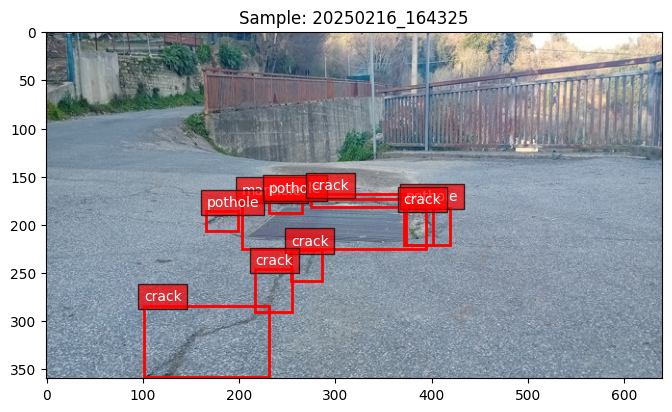

In [9]:
import json
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path

# Đọc tập train.jsonl và xem mẫu dữ liệu
train_file = Path("data/splits/train.jsonl")
if train_file.exists():
    with open(train_file, "r", encoding="utf-8") as f:
        samples = [json.loads(line) for line in f]
    print(f"Tổng số ảnh tập train: {len(samples)}")
    print("Mẫu dữ liệu đầu tiên:")
    print(json.dumps(samples[0], indent=2))

    # Vẽ bounding box trực quan hoá
    s = samples[0]
    img_path = Path("data") / s["image_path"]
    if img_path.exists():
        im = Image.open(img_path)
        fig, ax = plt.subplots(figsize=(8, 4.5))
        ax.imshow(im)
        for obj in s["objects"]:
            xc, yc, w, h = obj["yolo"]
            W, H = s["width"], s["height"]
            x1, y1 = (xc - w/2) * W, (yc - h/2) * H
            bw, bh = w * W, h * H
            rect = patches.Rectangle((x1, y1), bw, bh, linewidth=2, edgecolor='red', facecolor='none')
            ax.add_patch(rect)
            ax.text(x1, y1 - 5, obj["label"], color='white', bbox=dict(facecolor='red', alpha=0.7))
        plt.title(f"Sample: {s['image_id']}")
        plt.show()


## 2. Nhãn: YOLO → JSON thang 0–1000


In [10]:
def yolo_to_box(label, yolo):
    """Chuyển toạ độ YOLO [xc, yc, w, h] chuẩn hoá [0, 1] sang thang số nguyên 0-1000 [x1, y1, x2, y2]."""
    xc, yc, w, h = yolo
    x1 = round((xc - w / 2) * 1000)
    y1 = round((yc - h / 2) * 1000)
    x2 = round((xc + w / 2) * 1000)
    y2 = round((yc + h / 2) * 1000)
    x1 = max(0, min(1000, x1))
    y1 = max(0, min(1000, y1))
    x2 = max(x1 + 1, min(1000, x2))
    y2 = max(y1 + 1, min(1000, y2))
    return {"label": label, "bbox_2d": [x1, y1, x2, y2]}

def objects_to_answer(objects):
    """Sắp xếp box theo thứ tự trên->dưới, trái->phải và xuất chuỗi JSON rút gọn."""
    boxes = [yolo_to_box(o["label"], o["yolo"]) for o in objects]
    boxes.sort(key=lambda b: (b["bbox_2d"][1], b["bbox_2d"][0]))
    return json.dumps(boxes, separators=(",", ":"))

PROMPT_TEXT = (
    "Locate road damage in this image. Detect 'pothole', 'crack', and 'manhole'. "
    "Output coordinates on a 0-1000 normalized scale strictly as a JSON list of objects: "
    "[{\"label\": \"pothole\", \"bbox_2d\": [x1, y1, x2, y2]}]. Return [] if no damage is found."
)

# Test thử hàm chuyển đổi
test_objs = [{"label": "pothole", "yolo": [0.5, 0.5, 0.2, 0.2]}]
print("Test objects_to_answer:", objects_to_answer(test_objs))


Test objects_to_answer: [{"label":"pothole","bbox_2d":[400,400,600,600]}]


## 3. E0: zero-shot


In [17]:
import torch
import json
from PIL import Image
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration, BitsAndBytesConfig
from pathlib import Path

def run_e0_inference():
    quantization = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
        llm_int8_skip_modules=["visual", "lm_head"]
    )

    model_id = "Qwen/Qwen3-VL-4B-Instruct"
    print(f"Nạp model {model_id} zero-shot...")
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        model_id,
        quantization_config=quantization,
        torch_dtype=torch.float16,
        device_map={"": 0}
    )
    processor = AutoProcessor.from_pretrained(model_id)
    processor.tokenizer.padding_side = "left"

    test_file = Path("data/splits/test.jsonl")
    if not test_file.exists():
        print("Chưa có data/splits/test.jsonl. Bỏ qua chạy thật.")
        return

    with open(test_file, "r", encoding="utf-8") as f:
        test_entries = [json.loads(line) for line in f]

    work_dir = Path("work")
    work_dir.mkdir(parents=True, exist_ok=True)
    out_path = work_dir / "e0.jsonl"

    print(f"Bắt đầu suy luận E0 trên {len(test_entries)} ảnh...")
    with open(out_path, "w", encoding="utf-8") as out_f:
        for entry in test_entries:
            img_path = Path("data") / entry["image_path"]
            img = Image.open(img_path).convert("RGB")
            messages = [{
                "role": "user",
                "content": [
                    {"type": "image", "image": img},
                    {"type": "text", "text": PROMPT_TEXT}
                ]
            }]
            inputs = processor.apply_chat_template(
                messages, tokenize=True, add_generation_prompt=True,
                return_dict=True, return_tensors="pt", padding=True
            ).to("cuda")

            prompt_len = inputs.input_ids.shape[1]
            with torch.no_grad():
                out = model.generate(**inputs, max_new_tokens=256, do_sample=False)
            raw = processor.decode(out[0, prompt_len:], skip_special_tokens=True)
            out_f.write(json.dumps({"image_id": entry["image_id"], "raw": raw}) + "\n")
    print(f"Đã ghi kết quả E0 vào {out_path}")

run_e0_inference()

Nạp model Qwen/Qwen3-VL-4B-Instruct zero-shot...


config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


Bắt đầu suy luận E0 trên 311 ảnh...


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

Đã ghi kết quả E0 vào work/e0.jsonl


In [18]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json


E0 [test] n=311 valid=0.923 P=0.120 R=0.074 F1=0.091 CI95=0.067-0.117 meanIoU=0.602 FP/img=1.02
   pothole  P=0.368 R=0.116 F1=0.176
   crack    P=0.028 R=0.020 F1=0.023
   manhole  P=0.215 R=0.141 F1=0.170


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss


In [19]:
def encode_example(processor, image, prompt, answer):
    """Mã hoá mẫu học với chat template và mask loss (labels = -100 trên phần prompt và ảnh)."""
    user_msg = [{"role": "user", "content": [{"type": "image", "image": image}, {"type": "text", "text": prompt}]}]
    full_msgs = user_msg + [{"role": "assistant", "content": [{"type": "text", "text": answer}]}]

    prompt_enc = processor.apply_chat_template(
        user_msg, add_generation_prompt=True,
        tokenize=True, return_dict=True, return_tensors="pt"
    )
    full_enc = processor.apply_chat_template(
        full_msgs, add_generation_prompt=False,
        tokenize=True, return_dict=True, return_tensors="pt"
    )

    n = prompt_enc.input_ids.shape[1]
    assert (full_enc.input_ids[0, :n] == prompt_enc.input_ids[0]).all(), "Prompt phải là tiền tố của chuỗi đầy đủ"

    labels = full_enc.input_ids.clone()
    labels[:, :n] = -100  # Chỉ tính loss trên phần trả lời (JSON nhãn)
    full_enc["labels"] = labels
    return full_enc

def collate_fn(batch):
    """Collate batch: pad input_ids/labels, nối pixel_values theo chiều 0."""
    pad_id = 0
    max_len = max(x["input_ids"].shape[1] for x in batch)

    batch_input_ids = []
    batch_attention_mask = []
    batch_labels = []

    for item in batch:
        cur_len = item["input_ids"].shape[1]
        pad_len = max_len - cur_len

        batch_input_ids.append(torch.nn.functional.pad(item["input_ids"], (0, pad_len), value=pad_id))
        batch_attention_mask.append(torch.nn.functional.pad(item["attention_mask"], (0, pad_len), value=0))
        batch_labels.append(torch.nn.functional.pad(item["labels"], (0, pad_len), value=-100))

    out = {
        "input_ids": torch.cat(batch_input_ids, dim=0),
        "attention_mask": torch.cat(batch_attention_mask, dim=0),
        "labels": torch.cat(batch_labels, dim=0),
    }
    if "pixel_values" in batch[0]:
        out["pixel_values"] = torch.cat([x["pixel_values"] for x in batch], dim=0)
    if "image_grid_thw" in batch[0]:
        out["image_grid_thw"] = torch.cat([x["image_grid_thw"] for x in batch], dim=0)
    return out


## 5. Setup LoRA / đóng băng cho E1, E2, E3


In [20]:
from peft import LoraConfig, get_peft_model

def apply_setup(model, setup_name):
    """Áp dụng cấu hình đóng băng và LoRA cho E1, E2, E3 theo GUIDE bước 5."""
    for p in model.parameters():
        p.requires_grad = False
    model.enable_input_require_grads()

    # Target modules
    llm_targets = [
        r"model\.language_model\.layers\.\d+\.self_attn\.(q|k|v|o)_proj",
        r"model\.language_model\.layers\.\d+\.mlp\.(gate|up|down)_proj"
    ]
    vit_targets = [
        r"model\.visual\.blocks\.\d+\.attn\.(qkv|proj)",
        r"model\.visual\.blocks\.\d+\.mlp\.(linear_fc1|linear_fc2)"
    ]

    if setup_name in ("E1", "E2"):
        target_regex = "(" + "|".join(llm_targets) + ")"
    elif setup_name == "E3":
        target_regex = "(" + "|".join(llm_targets + vit_targets) + ")"
    else:
        raise ValueError(f"Setup không hợp lệ: {setup_name}")

    lora_config = LoraConfig(
        r=16,
        lora_alpha=32,
        lora_dropout=0.05,
        target_modules=target_regex
    )
    model = get_peft_model(model, lora_config)

    # Mở đầy đủ Projector ở float32 cho E2 và E3
    if setup_name in ("E2", "E3"):
        for name, param in model.named_parameters():
            if "visual.merger" in name or "visual.deepstack_merger_list" in name:
                param.data = param.data.to(torch.float32)
                param.requires_grad = True

    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    all_params = sum(p.numel() for p in model.parameters())
    print(f"[{setup_name}] Tham số huấn luyện: {trainable_params:,} / {all_params:,} ({100*trainable_params/all_params:.2f}%)")
    return model, trainable_params


## 6. Vòng huấn luyện


In [21]:
import time
from torch.optim import AdamW
from torch.amp import autocast, GradScaler
from transformers import get_cosine_schedule_with_warmup

def train_model(model, train_dataloader, setup_name="E1", max_steps=300, lr=2e-4, grad_accum=4):
    """Vòng huấn luyện theo GUIDE bước 6 với gradient checkpointing và autocast fp16."""
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.config.use_cache = False

    params_to_opt = [p for p in model.parameters() if p.requires_grad]
    optimizer = AdamW(params_to_opt, lr=lr, weight_decay=0.0)
    scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps=int(max_steps * 0.05), num_training_steps=max_steps)
    scaler = GradScaler("cuda")

    torch.cuda.reset_peak_memory_stats()
    start_time = time.time()
    step = 0
    model.train()

    print(f"Bắt đầu huấn luyện {setup_name} ({max_steps} bước tối ưu)...")
    accum_loss = 0.0
    optimizer.zero_grad()

    while step < max_steps:
        for batch in train_dataloader:
            batch = {k: v.to("cuda") for k, v in batch.items()}
            with autocast(device_type="cuda", dtype=torch.float16):
                outputs = model(**batch)
                loss = outputs.loss / grad_accum

            if not torch.isfinite(loss):
                raise RuntimeError("Loss tràn số / nan!")

            scaler.scale(loss).backward()
            accum_loss += loss.item() * grad_accum

            if (step + 1) % grad_accum == 0:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(params_to_opt, 1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()
                scheduler.step()
                step += 1

                if step % 50 == 0 or step == max_steps:
                    print(f"Step {step}/{max_steps} - Loss: {accum_loss / 50:.4f}")
                    accum_loss = 0.0

            if step >= max_steps:
                break

    train_minutes = (time.time() - start_time) / 60.0
    peak_vram_gb = torch.cuda.max_memory_allocated() / (1024 ** 3)
    print(f"Hoàn thành {setup_name}: {train_minutes:.1f} phút, VRAM đỉnh: {peak_vram_gb:.2f} GB")

    # Lưu adapter và Projector weights
    save_dir = Path(f"work/{setup_name.lower()}_adapter")
    model.save_pretrained(save_dir)
    if setup_name in ("E2", "E3"):
        extra = {n: p.data.cpu() for n, p in model.named_parameters() if ("visual.merger" in n or "visual.deepstack_merger_list" in n)}
        torch.save(extra, save_dir / "projector_weights.pt")

    return {
        "trainable_params": sum(p.numel() for p in params_to_opt),
        "peak_vram_gb": round(peak_vram_gb, 2),
        "train_minutes": round(train_minutes, 2)
    }


## 7. Suy luận và chấm E1–E3


In [22]:
def run_inference_and_score(setup_name, meta):
    """Suy luận trên test split và ghi file evidence theo GUIDE bước 7."""
    pred_file = f"work/{setup_name.lower()}.jsonl"
    out_evidence = f"report/evidence/{setup_name.lower()}.json"

    meta_args = [
        f"--meta trainable_params={meta['trainable_params']}",
        f"--meta peak_vram_gb={meta['peak_vram_gb']}",
        f"--meta train_minutes={meta['train_minutes']}"
    ]
    cmd = f"python scripts/score.py --pred {pred_file} --name {setup_name} --out {out_evidence} " + " ".join(meta_args)
    print("Chạy chấm điểm:", cmd)
    return cmd


## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)


In [23]:
# E4: Ablation trên rank LoRA (r=4 vs r=64)
# E5 (Bonus): Hàm reward IoU cho GRPO
from scripts.score import parse_output, iou_xyxy

def compute_reward(completion, gt_boxes):
    """Hàm reward theo GUIDE bước 9: reward = 0.2*valid + 0.8 * tổng_iou / max(n_gt, n_pred, 1)."""
    preds = parse_output(completion)
    if preds is None:
        return 0.0  # JSON hỏng

    if not gt_boxes and not preds:
        return 1.0

    pairs = []
    for g in gt_boxes:
        for p in preds:
            if g["label"] == p["label"]:
                iou = iou_xyxy(g["bbox"], p["bbox"])
                if iou >= 0.5:
                    pairs.append((iou, g, p))

    pairs.sort(key=lambda x: x[0], reverse=True)
    matched_g, matched_p = set(), set()
    total_iou = 0.0
    for iou, g, p in pairs:
        gid, pid = id(g), id(p)
        if gid not in matched_g and pid not in matched_p:
            matched_g.add(gid)
            matched_p.add(pid)
            total_iou += iou

    denom = max(len(gt_boxes), len(preds), 1)
    return 0.2 + 0.8 * (total_iou / denom)

# Test reward function
gt = [{"label": "pothole", "bbox": (400, 400, 600, 600)}]
perfect_pred = '[{"label": "pothole", "bbox_2d": [400, 400, 600, 600]}]'
bad_json = 'malformed json'
print("Reward hoàn hảo:", compute_reward(perfect_pred, gt))
print("Reward JSON hỏng:", compute_reward(bad_json, gt))


Reward hoàn hảo: 1.0
Reward JSON hỏng: 0.0


In [24]:
!python scripts/check_submission.py


[PASS] evidence e0
[PASS] evidence e1
[PASS] evidence e2
[PASS] evidence e3
[PASS] evidence e4 — 2 file
[PASS] e1 meta
[PASS] e2 meta
[PASS] e3 meta
[PASS] dataset_version nhất quán — ['d10-21e4070301']
[PASS] khớp data/splits/meta.json
[PASS] REPORT.md đã điền — còn chuỗi '<điền'
[PASS] git commits — 6/5
[PASS] git forbidden files

0 FAIL, 0 WARN
